In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import GroupShuffleSplit
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

1. Load the data

In [11]:
# fetch dataset 
mice_protein_expression = fetch_ucirepo(id=342) 
  
# data (as pandas dataframes) 
X = mice_protein_expression.data.features 
y = mice_protein_expression.data.targets 
  
# metadata 
print(mice_protein_expression.metadata) 
  
# variable information 
print(mice_protein_expression.variables) 


{'uci_id': 342, 'name': 'Mice Protein Expression', 'repository_url': 'https://archive.ics.uci.edu/dataset/342/mice+protein+expression', 'data_url': 'https://archive.ics.uci.edu/static/public/342/data.csv', 'abstract': 'Expression levels of 77 proteins measured in the cerebral cortex of 8 classes of control and Down syndrome mice exposed to context fear conditioning, a task used to assess associative learning.', 'area': 'Biology', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 1080, 'num_features': 80, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': ['MouseID'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2015, 'last_updated': 'Tue Apr 16 2024', 'dataset_doi': '10.24432/C50S3Z', 'creators': ['Clara Higuera', 'Katheleen Gardiner', 'Krzysztof Cios'], 'intro_paper': {'ID': 475, 'type': 'NATIVE', 'title': 'Self-Organizing Feature Maps Identify Proteins Critical

2. Data preparation and cleaning

In [12]:
# Merging identifiers, features (proteins + metadata), and target (class) into a single DataFrame
mice = pd.concat([
    mice_protein_expression.data.ids, 
    X, # Features (proteins + metadata)
    y  # Class (target variable)
], axis=1)

# Creating a derived variable for grouping (biological mouse identifier)
# Example: from "309_1" we create "309"
mice["mouse_id"] = mice["MouseID"].astype(str).str.rsplit("_", n=1).str[0]

# Defining the list of purely protein columns (77 in total)
exclude_cols = ['MouseID', 'mouse_id', 'Genotype', 'Treatment', 'Behavior', 'class']
protein_cols = [c for c in mice.columns if c not in exclude_cols]

# Checking the result
print(f"Total dimensions of the table: {mice.shape}")
print(f"Number of unique biological mice: {mice['mouse_id'].nunique()}")
print(f"Number of purely protein features: {len(protein_cols)}")

Total dimensions of the table: (1080, 83)
Number of unique biological mice: 72
Number of purely protein features: 77


3. EDA & Diagnostics

Total number of missing values in proteins: 1396
Number of full duplicate rows: 0
Number of mice with a different number of replicates: 0



/var/folders/fh/53s0xg911ln39w5cjz0l_wwc0000gn/T/ipykernel_36834/1573418689.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=mice, x='Genotype', ax=axes[0, 0], palette='pastel')
/var/folders/fh/53s0xg911ln39w5cjz0l_wwc0000gn/T/ipykernel_36834/1573418689.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=mice, x='Genotype', y='DYRK1A_N', ax=axes[1, 0], palette='pastel')


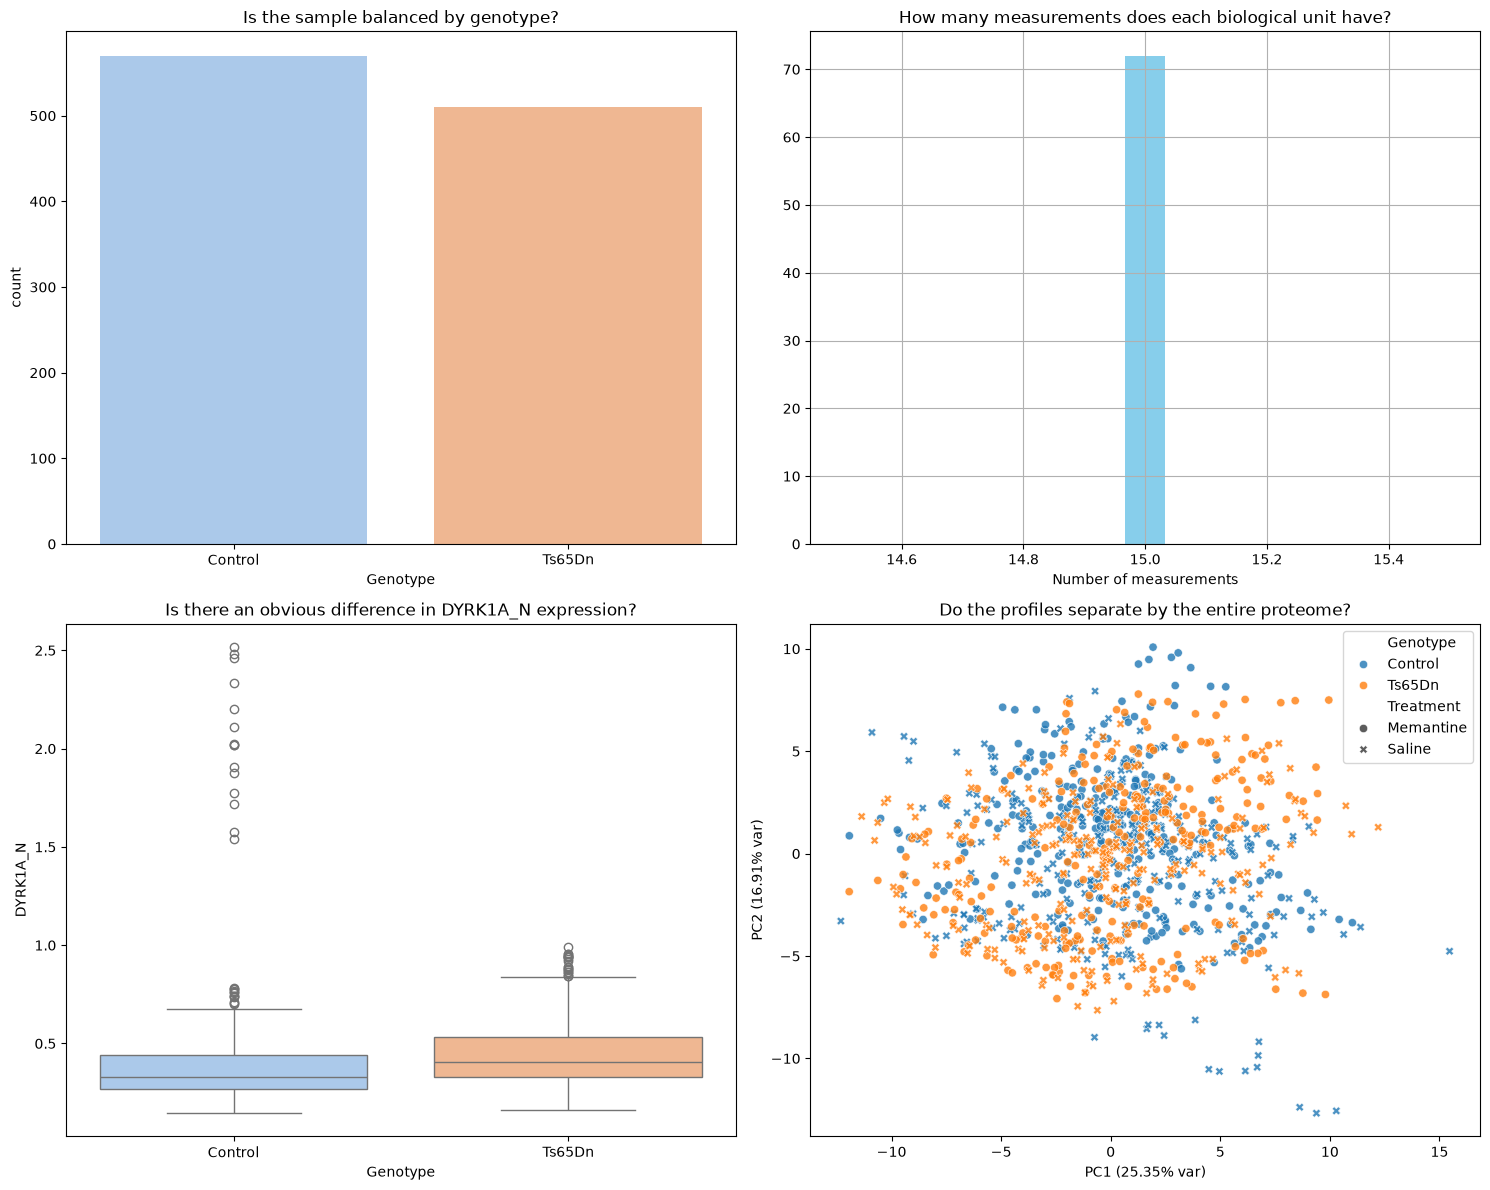

In [13]:
# Exploratory Data Analysis (EDA): Checking for missing values, duplicates, and invalid measurements
missing_total = mice[protein_cols].isna().sum().sum()
print(f"Total number of missing values in proteins: {missing_total}")

duplicates = mice.duplicated().sum()
print(f"Number of full duplicate rows: {duplicates}")

measurements_per_mouse = mice.groupby('mouse_id').size()
invalid_mice = measurements_per_mouse[measurements_per_mouse != 15]
print(f"Number of mice with a different number of replicates: {len(invalid_mice)}\n")

# Visualizing the data
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Graph 1: Checking for balance in Genotype
sns.countplot(data=mice, x='Genotype', ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('Is the sample balanced by genotype?')

# Graph 2: Checking the number of measurements per biological unit
measurements_per_mouse.hist(ax=axes[0, 1], bins=15, color='skyblue')
axes[0, 1].set_title('How many measurements does each biological unit have?')
axes[0, 1].set_xlabel('Number of measurements')

# Graph 3: Checking for obvious differences in DYRK1A_N expression
sns.boxplot(data=mice, x='Genotype', y='DYRK1A_N', ax=axes[1, 0], palette='pastel')
axes[1, 0].set_title('Is there an obvious difference in DYRK1A_N expression?')

# Graph 4: Overall data structure (PCA)
# For PCA temporarily fill missing values with median
imputer_eda = SimpleImputer(strategy='median')
X_eda = imputer_eda.fit_transform(mice[protein_cols])
X_scaled = StandardScaler().fit_transform(X_eda)

pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=mice['Genotype'], style=mice['Treatment'], ax=axes[1, 1], alpha=0.8)
axes[1, 1].set_title('Do the profiles separate by the entire proteome?')
axes[1, 1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} var)')
axes[1, 1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} var)')

plt.tight_layout()
plt.show()

4. Preparation, confounding, split, imputation and validation

In [14]:
# --- Preparation ---
# Separating features (X), target (y), and groups (mouse_id) for further analysis
X = mice[protein_cols].copy()
y = mice['Genotype'].copy()
groups = mice['mouse_id'].copy()

# --- Confounding and distribution structure ---
print("--- Validation of Confounding ---")
print("Is the experimental design balanced (Treatment/Behavior) with respect to our target (Genotype)?")
confounding_check = pd.crosstab(mice['Genotype'], [mice['Treatment'], mice['Behavior']])
print(confounding_check)
print("\n")

# --- Split ---
# Use GroupShuffleSplit to ensure that all measurements from the same biological mouse are either in the training set or the test set, but not both. This prevents data leakage and ensures that our model is evaluated on truly unseen data.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)

for train_idx, test_idx in splitter.split(X, y, groups=groups):
    X_train_raw = X.iloc[train_idx].copy()
    X_test_raw  = X.iloc[test_idx].copy()
    y_train = y.iloc[train_idx].copy()
    y_test  = y.iloc[test_idx].copy()
    groups_train = groups.iloc[train_idx].copy()
    groups_test  = groups.iloc[test_idx].copy()

# --- Imputation (dealing with 1396 missing values) ---
# CRITICAL: fit only on the training set!
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=protein_cols, index=X_train_raw.index)
X_test  = pd.DataFrame(imputer.transform(X_test_raw), columns=protein_cols, index=X_test_raw.index)

# --- Validation ---
print("--- Validation of the Split ---")
train_mice_set = set(groups_train)
test_mice_set = set(groups_test)
print(f"Size of X_train: {X_train.shape}, Unique mice: {len(train_mice_set)}")
print(f"Size of X_test:  {X_test.shape}, Unique mice: {len(test_mice_set)}")
print(f"Number of mice that ended up in both Train and Test: {len(train_mice_set.intersection(test_mice_set))} (SHOULD BE 0!)")
print(f"Missing values in X_train after imputation: {X_train.isna().sum().sum()}")

--- Validation of Confounding ---
Is the experimental design balanced (Treatment/Behavior) with respect to our target (Genotype)?
Treatment Memantine      Saline     
Behavior        C/S  S/C    C/S  S/C
Genotype                            
Control         150  150    135  135
Ts65Dn          135  135    105  135


--- Validation of the Split ---
Size of X_train: (810, 77), Unique mice: 54
Size of X_test:  (270, 77), Unique mice: 18
Number of mice that ended up in both Train and Test: 0 (SHOULD BE 0!)
Missing values in X_train after imputation: 0


5. Extended diagnostics (C)

In [ ]:
# --- Categories: unusual or inconsistent labels ---
for col in ['Genotype', 'Treatment', 'Behavior', 'class']:
    print(f"{col}: {mice[col].unique().tolist()}")
    print(mice[col].value_counts().to_string(), "\n")

Genotype: ['Control', 'Ts65Dn']
Genotype
Control    570
Ts65Dn     510 

Treatment: ['Memantine', 'Saline']
Treatment
Memantine    570
Saline       510 

Behavior: ['C/S', 'S/C']
Behavior
S/C    555
C/S    525 

class: ['c-CS-m', 'c-SC-m', 'c-CS-s', 'c-SC-s', 't-CS-m', 't-SC-m', 't-CS-s', 't-SC-s']
class
c-CS-m    150
c-SC-m    150
c-CS-s    135
c-SC-s    135
t-CS-m    135
t-SC-m    135
t-SC-s    135
t-CS-s    105 



In [ ]:
# --- Implausible protein values: non-finite, negative, zero ---
vals = mice[protein_cols]
n_inf = np.isinf(vals.to_numpy(dtype=float)).sum()
n_neg = (vals < 0).sum().sum()
n_zero = (vals == 0).sum().sum()
print(f"Non-finite (inf) values : {n_inf}")
print(f"Negative values         : {n_neg}")
print(f"Exact-zero values       : {n_zero}")
print("\nValue range across all proteins:")
print(f"  min = {vals.min().min():.4f}, max = {vals.max().max():.4f}")

Non-finite (inf) values : 0
Negative values         : 1
Exact-zero values       : 0

Value range across all proteins:
  min = -0.0620, max = 8.4826


Protein pairs with |r| > 0.9:
protein_A  protein_B      |r|
    ARC_N      pS6_N 1.000000
 DYRK1A_N     BRAF_N 0.959578
 DYRK1A_N    ITSN1_N 0.959512
    NR1_N     pNR1_N 0.947872
 DYRK1A_N     pERK_N 0.945719
   pERK_N     BRAF_N 0.926984
  ITSN1_N     BRAF_N 0.917608
    NR1_N Bcatenin_N 0.914610
   pNR1_N    pNR2B_N 0.906504
  ITSN1_N     pERK_N 0.906289


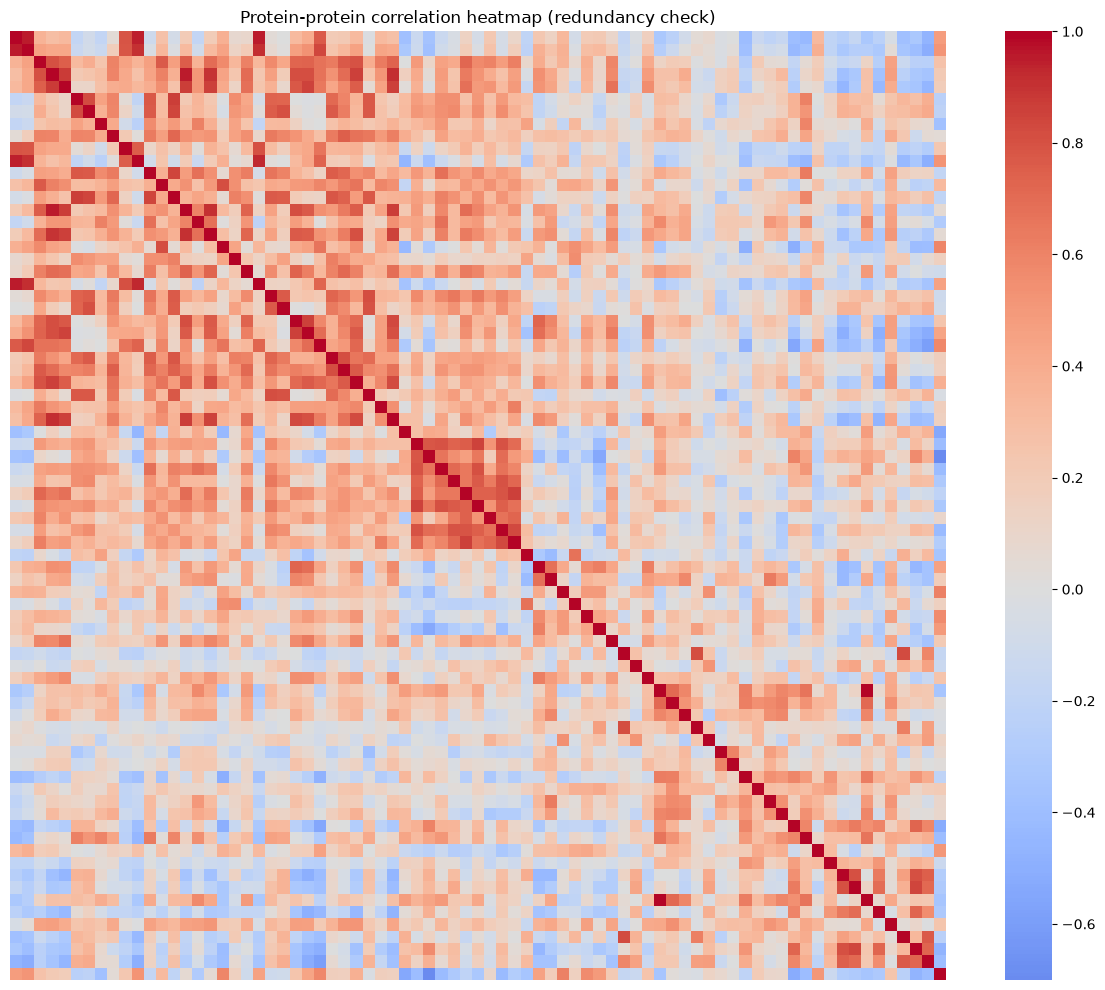

In [18]:
# --- Redundant / highly correlated proteins ---
corr = mice[protein_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = (upper.stack()
                   .sort_values(ascending=False)
                   .reset_index()
                   .rename(columns={'level_0':'protein_A','level_1':'protein_B',0:'|r|'}))
print("Protein pairs with |r| > 0.9:")
print(high_pairs[high_pairs['|r|'] > 0.9].to_string(index=False))

plt.figure(figsize=(12, 10))
sns.heatmap(mice[protein_cols].corr(), cmap='coolwarm', center=0,
            xticklabels=False, yticklabels=False)
plt.title('Protein-protein correlation heatmap (redundancy check)')
plt.tight_layout()
plt.show()

In [19]:
# --- Leakage check: is any candidate feature a deterministic part of y? ---
# `class` is built from Genotype+Behavior+Treatment, so it fully encodes the target.
print("Does composite `class` determine Genotype? (each class -> one genotype)")
print(pd.crosstab(mice['class'], mice['Genotype']))

Does composite `class` determine Genotype? (each class -> one genotype)
Genotype  Control  Ts65Dn
class                    
c-CS-m        150       0
c-CS-s        135       0
c-SC-m        150       0
c-SC-s        135       0
t-CS-m          0     135
t-CS-s          0     105
t-SC-m          0     135
t-SC-s          0     135


6. Preparation: removal rule vs imputation rule

In [20]:
# --- Missingness per protein ---
miss_per_protein = (mice[protein_cols].isna().mean() * 100).sort_values(ascending=False)
print("Top proteins by % missing:")
print(miss_per_protein.head(10).round(2).to_string())

# --- Option A: defensible REMOVAL rule ---
# Drop proteins missing in more than 5% of measurements; keep the rest.
MISS_THRESHOLD = 5.0
proteins_keep = miss_per_protein[miss_per_protein <= MISS_THRESHOLD].index.tolist()
proteins_drop = miss_per_protein[miss_per_protein >  MISS_THRESHOLD].index.tolist()
print(f"\nRemoval rule (> {MISS_THRESHOLD}% missing): "
      f"keep {len(proteins_keep)} proteins, drop {len(proteins_drop)}")
print("Dropped:", proteins_drop)

# --- Option B: IMPUTATION rule (median, fit on train only) --- already applied in sec. 4.
print(f"\nImputation rule: keep all 77 proteins, impute "
      f"{int(mice[protein_cols].isna().sum().sum())} missing cells with train median.")

Top proteins by % missing:
BCL2_N        26.39
H3MeK4_N      25.00
BAD_N         19.72
EGR1_N        19.44
H3AcK18_N     16.67
pCFOS_N        6.94
ELK_N          1.67
Bcatenin_N     1.67
MEK_N          0.65
P38_N          0.28

Removal rule (> 5.0% missing): keep 71 proteins, drop 6
Dropped: ['BCL2_N', 'H3MeK4_N', 'BAD_N', 'EGR1_N', 'H3AcK18_N', 'pCFOS_N']

Imputation rule: keep all 77 proteins, impute 1396 missing cells with train median.


7. Split strategy: stratification vs grouping

In [21]:
from sklearn.model_selection import StratifiedGroupKFold

# Target balance at the MOUSE level (the independent unit) -> decides stratification.
mouse_geno = mice.groupby('mouse_id')['Genotype'].first()
print("Genotype balance at mouse level:")
print(mouse_geno.value_counts(normalize=True).round(3).to_string())

# Plain GroupShuffleSplit does not guarantee class balance across the split.
# StratifiedGroupKFold keeps mice intact AND balances Genotype -> compatible.
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
tr_idx, te_idx = next(sgkf.split(X, y, groups=groups))
print("\nStratifiedGroupKFold fold check:")
print("train genotype %:", y.iloc[tr_idx].value_counts(normalize=True).round(3).to_dict())
print("test  genotype %:", y.iloc[te_idx].value_counts(normalize=True).round(3).to_dict())
print("mouse overlap   :",
      len(set(groups.iloc[tr_idx]) & set(groups.iloc[te_idx])), "(should be 0)")

Genotype balance at mouse level:
Genotype
Control    0.528
Ts65Dn     0.472

StratifiedGroupKFold fold check:
train genotype %: {'Control': 0.519, 'Ts65Dn': 0.481}
test  genotype %: {'Control': 0.556, 'Ts65Dn': 0.444}
mouse overlap   : 0 (should be 0)


8. Confounding and distribution structure

class x Genotype (each class -> single genotype = direct encoding):
Genotype  Control  Ts65Dn
class                    
c-CS-m        150       0
c-CS-s        135       0
c-SC-m        150       0
c-SC-s        135       0
t-CS-m          0     135
t-CS-s          0     105
t-SC-m          0     135
t-SC-s          0     135 

Measurements per mouse by genotype (describe):
          count  mean  std   min   25%   50%   75%   max
Genotype                                                
Control    38.0  15.0  0.0  15.0  15.0  15.0  15.0  15.0
Ts65Dn     34.0  15.0  0.0  15.0  15.0  15.0  15.0  15.0


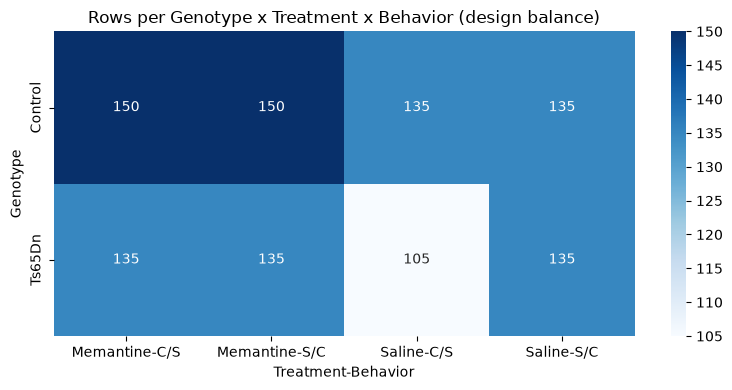

In [22]:
# --- Does the composite class encode the target directly? ---
print("class x Genotype (each class -> single genotype = direct encoding):")
print(pd.crosstab(mice['class'], mice['Genotype']), "\n")

# --- Rows per mouse, by genotype ---
rows_per_mouse = mice.groupby(['Genotype', 'mouse_id']).size()
print("Measurements per mouse by genotype (describe):")
print(rows_per_mouse.groupby('Genotype').describe().round(2))

# --- Treatment/Behavior balance across genotype (already computed, plotted) ---
ct = pd.crosstab(mice['Genotype'], [mice['Treatment'], mice['Behavior']])
plt.figure(figsize=(8, 4))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('Rows per Genotype x Treatment x Behavior (design balance)')
plt.tight_layout()
plt.show()

9. Deliverable

In [23]:
import os
os.makedirs('plots', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

def role(col):
    if col == 'MouseID':   return ('identifier', 'raw measurement-record id; excluded')
    if col == 'mouse_id':  return ('group', 'derived biological unit; used for grouping, excluded from X')
    if col == 'Genotype':  return ('target', 'prediction target (Control vs Ts65Dn)')
    if col == 'class':     return ('excluded', 'composite of genotype+behavior+treatment -> target leakage')
    if col in ('Treatment','Behavior'):
        return ('excluded', 'experimental-design factor; excluded to avoid design-based shortcut')
    return ('feature', '77 RPPA protein-expression measurement')

roles = pd.DataFrame([(c, *role(c)) for c in mice.columns],
                     columns=['column', 'role', 'justification'])
roles.to_csv('outputs/column_roles.csv', index=False)
print(roles.to_string(index=False))

         column       role                                                       justification
        MouseID identifier                                 raw measurement-record id; excluded
       DYRK1A_N    feature                              77 RPPA protein-expression measurement
        ITSN1_N    feature                              77 RPPA protein-expression measurement
         BDNF_N    feature                              77 RPPA protein-expression measurement
          NR1_N    feature                              77 RPPA protein-expression measurement
         NR2A_N    feature                              77 RPPA protein-expression measurement
         pAKT_N    feature                              77 RPPA protein-expression measurement
        pBRAF_N    feature                              77 RPPA protein-expression measurement
      pCAMKII_N    feature                              77 RPPA protein-expression measurement
        pCREB_N    feature                        

In [24]:
# --- Missingness report ---
miss_report = pd.DataFrame({
    'pct_missing': (mice[protein_cols].isna().mean() * 100).round(3),
    'n_missing':    mice[protein_cols].isna().sum()
}).sort_values('pct_missing', ascending=False)
miss_report.to_csv('outputs/missingness_report.csv')
print(f"Total missing protein cells: {int(mice[protein_cols].isna().sum().sum())}")
print(f"Overall missing rate: {mice[protein_cols].isna().mean().mean()*100:.3f}%")
print(miss_report.head(10).to_string())

Total missing protein cells: 1396
Overall missing rate: 1.679%
            pct_missing  n_missing
BCL2_N           26.389        285
H3MeK4_N         25.000        270
BAD_N            19.722        213
EGR1_N           19.444        210
H3AcK18_N        16.667        180
pCFOS_N           6.944         75
ELK_N             1.667         18
Bcatenin_N        1.667         18
MEK_N             0.648          7
P38_N             0.278          3


In [25]:
# --- Save the ML-ready split ---
X_train.to_csv('outputs/X_train.csv')
X_test.to_csv('outputs/X_test.csv')
y_train.to_frame('Genotype').to_csv('outputs/y_train.csv')
y_test.to_frame('Genotype').to_csv('outputs/y_test.csv')
print("Saved: X_train, X_test, y_train, y_test ->", os.listdir('outputs'))

Saved: X_train, X_test, y_train, y_test -> ['missingness_report.csv', 'X_train.csv', 'column_roles.csv', 'y_train.csv', 'y_test.csv', 'X_test.csv']


10. Reproducibility

In [26]:
import sys, sklearn
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Python     :", sys.version.split()[0])
print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("seaborn    :", sns.__version__)
print("RANDOM_STATE:", RANDOM_STATE)
print("Shapes -> X_train:", X_train.shape, "X_test:", X_test.shape)

Python     : 3.11.16
pandas     : 3.0.5
numpy      : 2.4.6
scikit-learn: 1.9.0
seaborn    : 0.13.2
RANDOM_STATE: 42
Shapes -> X_train: (810, 77) X_test: (270, 77)
